Questo notebookl andalizza il dataset costruito nel Notebook01 per capire se è adatto alla costruzione di un sistema di raccomandazione.
In particolare analizzare la sparsità dei dati.

## 1-setup

In [109]:
#Se mancano pacchetti, esegui questa cella una sola volta.
%pip install -q "datasets==3.6.0" pandas pyarrow requests tqdm
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [110]:
from pathlib import Path
import json
import math
import warnings #gestire warnings
import numpy as np 
import pandas as pd
import pyarrow.parquet as pq 
import matplotlib.pyplot as plt 

warnings.filterwarnings("ignore", category=FutureWarning) #nasconde avvisi per avere output meno rumoroso
#impostazioni di pandas
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")  

## 2 percorsi file

In [111]:
#percorsi
CATEGORY="Electronics"

PROJECT_ROOT=Path(r"C:\Users\arsid\Desktop\Tesi-ecommerce")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "electronics_intersection" #percorso dati notebook01
ANALYSIS_DIR = PROCESSED_DIR / "analysis" #dove salvare risultati notebook02
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True) #la crea se non esiste già

#percorsi dei file prodotti nel notebook01
ITEMS_PATH = PROCESSED_DIR / "items.parquet"
QA_PATH = PROCESSED_DIR / "qa.parquet"
RATINGS_PATH = PROCESSED_DIR / "ratings.parquet"
SUMMARY_PATH = PROCESSED_DIR / "summary.json"

#controllo dei percorsi
print("Project root:", PROJECT_ROOT)
print("Processed dir:", PROCESSED_DIR)
print("Analysis dir:", ANALYSIS_DIR)


Project root: C:\Users\arsid\Desktop\Tesi-ecommerce
Processed dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection
Analysis dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\analysis


## 3 lettura dati parquet

In [112]:
#lettura dei metadata dei parquet
def parquet_info(path: Path)->dict:
    pf=pq.ParquetFile(path)
    return{
        "file":path.name,
        "rows":pf.metadata.num_rows,
        "row_groups":pf.metadata.num_row_groups,
        "columns": len(pf.schema_arrow.names),
        "column_names": ", ".join(pf.schema_arrow.names),
    }

parquet_infos=pd.DataFrame([
    parquet_info(ITEMS_PATH),
    parquet_info(QA_PATH),
    parquet_info(RATINGS_PATH),
])

parquet_infos

,file,rows,row_groups,columns,column_names
0,items.parquet,22974,1,12,"parent_asin, title, category, avg_rating, num_ratings, price, store, features_json, description_json, categories_jso..."
1,qa.parquet,180976,1,8,"qa_id, parent_asin, question, answer, questionType, answerType, answerTime, unixTime"
2,ratings.parquet,3484401,18,6,"user_id, parent_asin, asin, rating, timestamp, verified_purchase"


In [113]:
summary=json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
display(pd.DataFrame([summary]).T.rename(columns={0: "rows_from_summary_json"}))

,rows_from_summary_json
items,22974
qa,180976
ratings,3484401


## 4 caricamento dei dati

In [114]:
#caricamento dei dati
def parquet_columns(path: Path)-> list[str]: #funzione che restituisce i nomi delle colonne
    return pq.ParquetFile(path).schema_arrow.names

def columns_keep(path: Path, wanted: list[str])-> list[str]: #funzione che tiene solo le colonne richieste
    available=set(parquet_columns(path))
    return [col for col in wanted if col in available]

items_df=pd.read_parquet(ITEMS_PATH)
qa_df=pd.read_parquet(QA_PATH)

wanted_rating_columns=[
    "user_id","parent_asin","asin","rating","timestamp","verified_purchase",
    "review_title","review_text",#se presenti le colonne testuali, in base a cosa si è scelto nel notebook 01
]

rating_columns=columns_keep(RATINGS_PATH,wanted_rating_columns)
ratings_df=pd.read_parquet(RATINGS_PATH,columns=rating_columns)

print("items_df:", items_df.shape)
print("qa_df:", qa_df.shape)
print("ratings_df:", ratings_df.shape)
print("Colonne rating caricate:", rating_columns)

items_df: (22974, 12)
qa_df: (180976, 8)
ratings_df: (3484401, 6)
Colonne rating caricate: ['user_id', 'parent_asin', 'asin', 'rating', 'timestamp', 'verified_purchase']


In [115]:
display(items_df.head(3))
display(qa_df.head(3))
display(ratings_df.head(3))

,parent_asin,title,category,avg_rating,num_ratings,price,store,features_json,description_json,categories_json,details_json,image_url
0,B00CFGZAT8,"Dock Audio Extender Adapter Converter Cable for iPod iPhone 4 4S iPhone 5 5S iPad, Samsung & Other Smart Phones",Portable Audio & Accessories,3.600000,45,NaN,iteck,[],[],"[""Electronics"", ""Computers & Accessories"", ""Tablet Accessories"", ""Chargers & Adapters""]","""{\""Brand Name\"": \""iTeck\"", \""Item Weight\"": \""0.8 ounces\"", \""Package Dimensions\"": \""6 x 4 x 0.3 inches; 0.8 Ounc...",https://m.media-amazon.com/images/I/41uTuqlHDSL._AC_.jpg
1,B00BGFTSGU,GGS Swivi HD DSLR LCD Universal Foldable Viewfinder Version II with 3.0X Magnification,Camera & Photo,3.700000,52,149.000000,Swivi,[],[],"[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Viewfinders""]","""{\""Product Dimensions\"": \""3.8 x 4.3 x 6.9 inches\"", \""Item Weight\"": \""0.705 ounces\"", \""Item model number\"": \""Sw...",https://m.media-amazon.com/images/I/41BUv5PjMDL._AC_.jpg
2,B00AZOIG9I,BM Premium 2-Pack of NP-85 Batteries and Charger Kit for FujiFilm FinePix S1 SL240 SL260 SL280 SL300 SL305 SL1000 Di...,Camera & Photo,4.700000,345,22.990000,BM Premium,"[""NP85 Li-ion Battery for FujiFilm FinePix SL240 SL260 SL280 SL300 SL305 SL1000 Digital Camera"", ""Battery Specificat...","[""Bring your digital camera back to life with a new battery. Make sure you never miss another once-in-a-lifetime mom...","[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Batteries & Chargers"", ""Batteries"", ""Camera Batteries""]","""{\""Package Dimensions\"": \""6.46 x 3.94 x 1.85 inches\"", \""Item Weight\"": \""6.7 ounces\"", \""Item model number\"": \""N...",https://m.media-amazon.com/images/I/71fbU-87TxL._AC_SL1500_.jpg


,qa_id,parent_asin,question,answer,questionType,answerType,answerTime,unixTime
0,0,0594033926,Is this cover the one that fits the old nook color? Which I believe is 8x5.,Yes this fits both the nook color and the same-shaped nook tablet,yes/no,Y,"Dec 27, 2013","1,388,131,200.000000"
1,1,0594033926,Does it fit Nook GlowLight?,No. The nook color or color tablet,yes/no,N,"Jan 5, 2015","1,420,444,800.000000"
2,2,0594033926,Would it fit Nook 1st Edition? 4.9in x 7.7in ?,"I don't think so. The nook color is 5 x 8 so not sure anything smaller would stay locked in, but would be close.",open-ended,NaN,2 days ago,NaN


,user_id,parent_asin,asin,rating,timestamp,verified_purchase
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B0047T79VS,B0047T79VS,3.000000,1344406083000,True
1,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B001FWYGJS,B001FWYGJS,4.000000,1427592277000,True
2,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B00BHC7ZTE,B00BHC7ZTE,5.000000,1432342265000,True


## 5 controlli di coerenza

In [116]:
#controlli generali di coerenza
def pct(numerator, denominator): #funzione che useremo anche dopo per calcolare la percentuale
    if denominator == 0:
        return np.nan
    return numerator/denominator *100

items_set=set(items_df["parent_asin"].dropna()) #insieme parentasin nei metadati, droppando valori nulli
ratings_items_set=set(ratings_df["parent_asin"].dropna()) #insieme parentasin dei rating
qa_items_set=set(qa_df["parent_asin"].dropna()) #insieme parentasin qa
#dizionario con statistiche generali del dataset
basic_stats={
    "num_product_items": items_df["parent_asin"].nunique(), #conta quanti prodotti unici nella tabella items
    "num_rating_rows": len(ratings_df), #conta quante righe di rating presenti
    "num_users":ratings_df["user_id"].nunique(dropna=True), #quanti utenti unici compaiono nei rating
    "num_products_with_ratings": ratings_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno un rating
    "num_qa_rows":len(qa_df), #quante righe di domande/risposte presenti
    "num_products_with_qa": qa_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno una domanda/risposta
    "items_parent_asin_unique": bool(items_df["parent_asin"].is_unique), #controlla se parent_asin è unico nella tabella items
    "ratings_products_all_in_items": ratings_items_set.issubset(items_set), #verifica se tutti i prodotti nei rating sono presenti anche nei metadati items
    "qa_products_all_in_items": qa_items_set.issubset(items_set), #controlla se tutti prodotti qa sono presenti anche nei metadati items
    "items_with_rating_pct": pct(len(items_set & ratings_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno un rating
    "items_with_qa_pct": pct(len(items_set & qa_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno una riga QA
}

basic_stats_df=pd.DataFrame.from_dict(basic_stats, orient="index", columns=["value"]) #converte dizionario delle stats generali in tabella pandas
display(basic_stats_df)

basic_stats_df.to_csv(ANALYSIS_DIR/"notebook02_basic_stats.csv")

,value
num_product_items,22974
num_rating_rows,3484401
num_users,2434619
num_products_with_ratings,22974
num_qa_rows,180976
num_products_with_qa,22974
items_parent_asin_unique,True
ratings_products_all_in_items,True
qa_products_all_in_items,True
items_with_rating_pct,100.000000


In [117]:
#se alcuni prodotti sono presenti nei ratings ma non in items (se esce 0 perfetto)
missing_rating_products = ratings_items_set - items_set
#se alcuni prodotti sono presenti nel QA ma assenti in items (se esce 0 perfetto)
missing_qa_products = qa_items_set - items_set
print("Prodotti in ratings ma non in items:", len(missing_rating_products))
print("Prodotti in qa ma non in items:", len(missing_qa_products))
if missing_rating_products:
    print("Esempi ratings fuori items:", list(missing_rating_products)[:5])
if missing_qa_products:
    print("Esempi QA fuori items:", list(missing_qa_products)[:5])

Prodotti in ratings ma non in items: 0
Prodotti in qa ma non in items: 0


## 6 controllo qualità dei dati

In [118]:
#ora bisogna controllare la qualità di questi dati
important_columns={ #dizionario con colonne importanti da controllare
    "items": ["parent_asin","title","category"],
    "qa": ["parent_asin","question","answer"],
    "ratings": ["user_id","parent_asin","rating"],
}
null_rows=[]
#scorriamo le tabelle e colonne da controllare
for df_name, cols in important_columns.items():
    df={"items":items_df, "qa":qa_df, "ratings":ratings_df}[df_name]
    for col in cols:
        if col in  df.columns:
            null_rows.append({
                "table":df_name,
                "column":col,
                "null_count":int(df[col].isna().sum()), #conta quanti valori nulli presenti nella colonna
                "null_pct": pct(int(df[col].isna().sum()), len(df)), #conta la percentuale di valori nulli nella colonna
            })

nulls_df=pd.DataFrame(null_rows)
nulls_df


,table,column,null_count,null_pct
0,items,parent_asin,0,0.000000
1,items,title,0,0.000000
2,items,category,0,0.000000
3,qa,parent_asin,0,0.000000
4,qa,question,0,0.000000
5,qa,answer,0,0.000000
6,ratings,user_id,0,0.000000
7,ratings,parent_asin,0,0.000000
8,ratings,rating,0,0.000000


In [119]:
#vediamo se ci sono rating nulli
invalid_rating_mask= ratings_df["rating"].isna() | ~ratings_df["rating"].between(1,5)
invalid_ratings=ratings_df.loc[invalid_rating_mask]
print("Rating nulli o fuori scala:", len(invalid_ratings))
if len(invalid_ratings)>0:
    display(invalid_ratings.head()) 


Rating nulli o fuori scala: 0


In [120]:
#calcoliamo distribuzione dei voti
rating_dist=(
    ratings_df["rating"].value_counts(dropna=False).sort_index().rename_axis("rating").reset_index(name="count")
)
rating_dist["pct"]=rating_dist["count"]/len(ratings_df)*100 #percentuale di ogni voto sul tot
rating_dist

,rating,count,pct
0,1.000000,399404,11.462630
1,2.000000,195919,5.622745
2,3.000000,264586,7.593443
3,4.000000,573679,16.464207
4,5.000000,2050813,58.856974


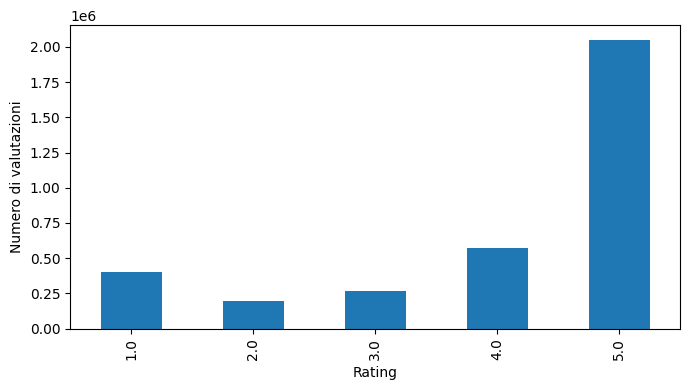

In [121]:
#schema dei dati visti sopra sui rating
plt.figure(figsize=(7,4))
rating_dist.dropna(subset=["rating"]).plot(
    x="rating",y="count",kind="bar",legend=False,ax=plt.gca()
)
#plt.title("Distribuzione dei rating nel dataset")
plt.xlabel("Rating")
plt.ylabel("Numero di valutazioni")
plt.tight_layout()
plt.show()

In [122]:
#funzione per capire se timestamp sono in sec o millisec
def timestamp_un(series:pd.Series)->str | None:
    values=pd.to_numeric(series.dropna(), errors="coerce").dropna() #converte timestamp in numeri
    if values.empty:
        return None
    median_value=values.median()
    if median_value>1e12: #se compatibile con millisecondi
        return "ms"
    if median_value>1e9: #se compatibile con secondi
        return "s"
    return None

timestamp_unit=timestamp_un(ratings_df["timestamp"]) #stima l'unità del timestamp
print("Unità stimata del timestamp: ",timestamp_unit)


ratings_df["datetime"]=pd.to_datetime(
    ratings_df["timestamp"], unit=timestamp_unit,errors="coerce" #passa a pandas la colonna timestamp da convertire
    )
print("data minima: ",ratings_df["datetime"].min())
print("data massima: ",ratings_df["datetime"].max())
display(ratings_df[["timestamp","datetime"]].head())


Unità stimata del timestamp:  ms
data minima:  1999-07-23 18:26:11
data massima:  2023-09-11 02:17:59.206000


,timestamp,datetime
0,1344406083000,2012-08-08 06:08:03.000
1,1427592277000,2015-03-29 01:24:37.000
2,1432342265000,2015-05-23 00:51:05.000
3,1419885573000,2014-12-29 20:39:33.000
4,1589664572977,2020-05-16 21:29:32.977


In [123]:
#controlliamo duplicati userid+parentasin
pair_columns=["user_id","parent_asin"]
duplicate_mask=ratings_df.duplicated(pair_columns,keep=False)#crea maschera che marca tutte le righe appartenenti a coppie utente-prodotto duplicate
num_duplicate_rows=int(duplicate_mask.sum()) #conta righe duplicate
num_duplicate_pairs=int(ratings_df.loc[duplicate_mask,pair_columns].drop_duplicates().shape[0]) #conta coppie duplicate
print("Righe coinvolte in duplicati user_id+parent_asin:", num_duplicate_rows)
print("Coppie duplicate distinte:", num_duplicate_pairs)

if num_duplicate_rows>0:
    display( #seleziona solo righe duplicate, e le ordina
        ratings_df.loc[duplicate_mask].sort_values(pair_columns+(["timestamp"] if "timestamp" in ratings_df.columns else [])).head(10)
    )


Righe coinvolte in duplicati user_id+parent_asin: 68896
Coppie duplicate distinte: 31666


,user_id,parent_asin,asin,rating,timestamp,verified_purchase,datetime
3446379,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446380,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446381,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446382,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446383,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
517149,AE22E3XNIF5TITEAJXHT55LD5QUQ,B0071369M2,B007136E0O,5.000000,1507983964568,True,2017-10-14 12:26:04.568
517150,AE22E3XNIF5TITEAJXHT55LD5QUQ,B0071369M2,B007136E0O,5.000000,1507983964568,True,2017-10-14 12:26:04.568
3440251,AE22IPEIUZH764VWYNIIVDM54YBA,B008KCSPRK,B008KCSPRK,1.000000,1397608765000,True,2014-04-16 00:39:25.000
3440252,AE22IPEIUZH764VWYNIIVDM54YBA,B008KCSPRK,B008KCSPRK,1.000000,1397608765000,True,2014-04-16 00:39:25.000
3355803,AE22LFQUJPE5ZLCCEWTOGCHJXURQ,B0090SVDEK,B0090SVDEK,5.000000,1347641749000,False,2012-09-14 16:55:49.000


,year,count,pct
0,1999,12,0.000344
1,2000,262,0.007519
2,2001,379,0.010877
3,2002,582,0.016703
4,2003,900,0.025829
5,2004,1369,0.039289
6,2005,3892,0.111698
7,2006,11739,0.336902
8,2007,35201,1.010245
9,2008,41699,1.196734


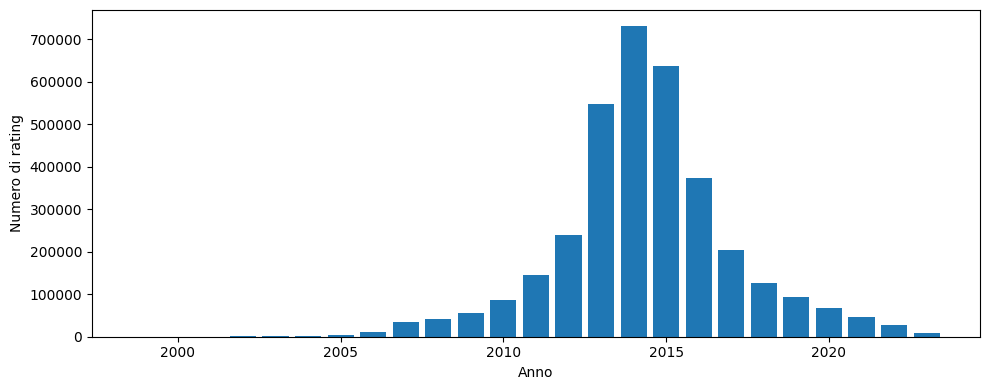

In [124]:
#andiamo ad analizzare le valutazioni per ogni anno
if "datetime" in ratings_df.columns:
    ratings_each_year =(
        ratings_df["datetime"]
        .dt.year
        .value_counts()
        .sort_index()
        .rename_axis("year")
        .reset_index(name="count")
    )

    ratings_each_year["pct"]=ratings_each_year["count"]/len(ratings_df)*100
    display(ratings_each_year)
    plt.figure(figsize=(10,4))
    plt.bar(ratings_each_year["year"], ratings_each_year["count"])
    #plt.title("Distribuzione dei rating per ogni anno")
    plt.xlabel("Anno")
    plt.ylabel("Numero di rating")
    plt.tight_layout()
    plt.show()

## 7 costruzione tabella nuova pulita

Costruiamo la tabella sistemata:
rimuoviamo le righe non valide, duplicate.

In [125]:
def build_int_table(ratings: pd.DataFrame) ->pd.DataFrame: #funzione per pulire e togliere duplicati
    base=ratings.copy() #crea copia
    base=base.dropna(subset=["user_id","parent_asin","rating"]) #rimuove righe senza utente, prodotto, rating
    base=base[base["rating"].between(1,5)].copy() #mantiene rating fra 1 e 5
    base=base.sort_values(["user_id","parent_asin","timestamp"]) #ordina valutazioni per utente, prodotto e timestamp
    interactions=base.drop_duplicates(["user_id","parent_asin"],keep="last").copy()#per ogni coppia tiene solo l'ultima

    return interactions.reset_index(drop=True) #restituisce interazioni pulite con indice ricreato da zero

interactions_df=build_int_table(ratings_df) #applica la funzione ai rating

print("Righe rating originali: ",f"{len(ratings_df):,}")
print("Interazioni dopo la pulizia:",f"{len(interactions_df):,}")
print("Righe rimosse nella pulizia:",f"{len(ratings_df)-len(interactions_df):,}")
display(interactions_df.head())

Righe rating originali:  3,484,401
Interazioni dopo la pulizia: 3,447,171
Righe rimosse nella pulizia: 37,230


,user_id,parent_asin,asin,rating,timestamp,verified_purchase,datetime
0,AE2222FRPDMNOMYOMCWIANTXP7UQ,B007ZHAYL6,B007ZHAYL6,5.000000,1419287222000,True,2014-12-22 22:27:02
1,AE22236AFRRSMQIKGG7TPTB75QEA,B000JREMTO,B000JREMTO,5.000000,1275251437000,True,2010-05-30 20:30:37
2,AE22236AFRRSMQIKGG7TPTB75QEA,B003ZDO2LM,B003ZDO2LM,5.000000,1311718723000,True,2011-07-26 22:18:43
3,AE22236AFRRSMQIKGG7TPTB75QEA,B005CG2AX2,B005CG2AX2,4.000000,1344043262000,False,2012-08-04 01:21:02
4,AE222ARFTTB3OUTW2RXSHTO3DBZQ,B001F7AJKI,B001F7AJKI,5.000000,1454448914000,True,2016-02-02 21:35:14


## 8 analisi degli utenti

Analizziamo gli utenti, quante interazioni ha ciascun utente

In [126]:
def analyze_quantilies(counts: pd.Series, name: str)-> pd.DataFrame: #funzione per riassumere conteggi
    quantiles=counts.quantile([0.25,0.50,0.75,0.90,0.95,0.99]).to_dict()
    data={
        "entity":name,
        "num_entities":counts.shape[0],
        "mean":counts.mean(),
        "median:":counts.median(),
        "min":counts.min(),
        "p25":quantiles.get(0.25),
        "p75":quantiles.get(0.75),
        "p90":quantiles.get(0.90),
        "p95":quantiles.get(0.95),
        "p99":quantiles.get(0.99),
        "max":counts.max(),
    }
    return pd.DataFrame([data])

user_counts=interactions_df["user_id"].value_counts()
user_summary=analyze_quantilies(user_counts, "users")
user_summary

,entity,num_entities,mean,median:,min,p25,p75,p90,p95,p99,max
0,users,2434619,1.415898,1.000000,1,1.000000,1.000000,2.000000,3.000000,6.000000,98


,interactions_per_user,num_users,percentage_users
0,1,1899158,78.006374
1,2,329271,13.524539
2,3,105842,4.347374
3,4,44524,1.828787
4,5-9,48425,1.989018
5,≥10,7399,0.303908


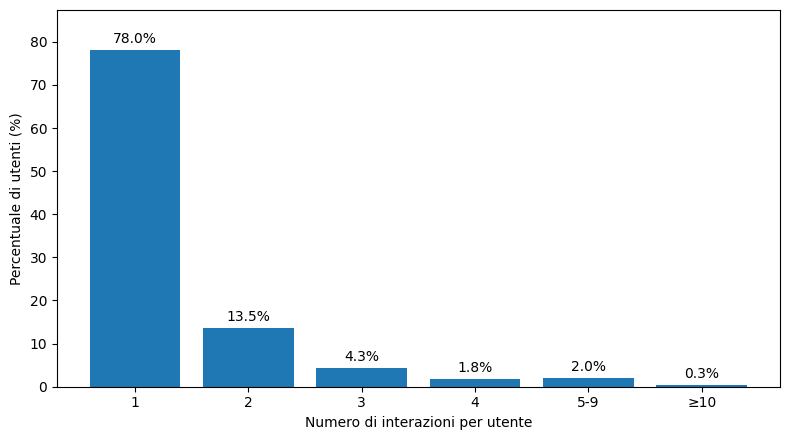

In [127]:
#Distribuzione degli utenti per numero di interazioni
#Raggruppamento pensato per una visualizzazione più leggibile nella tesi

user_interaction_groups =pd.Series({
    "1":(user_counts ==1).sum(),
    "2":(user_counts ==2).sum(),
    "3":(user_counts==3).sum(),
    "4":(user_counts==4).sum(),
    "5-9":((user_counts>= 5) & (user_counts <= 9)).sum(),
    "≥10":(user_counts>= 10).sum()
})

#Conversione in percentuale sul totale degli utenti
user_interaction_pct = (
    user_interaction_groups / user_interaction_groups.sum() * 100
)

#Tabella di controllo
user_interaction_distribution=pd.DataFrame({
    "interactions_per_user":user_interaction_groups.index,
    "num_users":user_interaction_groups.values,
    "percentage_users":user_interaction_pct.values
})

display(user_interaction_distribution)
plt.figure(figsize=(8,4.5))

bars=plt.bar(
    user_interaction_groups.index,
    user_interaction_pct.values
)

plt.xlabel("Numero di interazioni per utente")
plt.ylabel("Percentuale di utenti (%)")


plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in user_interaction_pct.values],
    padding=3
)

plt.ylim(0, user_interaction_pct.max() * 1.12)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR / "user_interactions_distribution_grouped.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [128]:
user_thresholds=[1,2,3,4,5,6,7,8,9,10,20,50] #soglie da testare minime di interazione per ogni utente
rows=[]

for t in user_thresholds:
    valid_users=user_counts[user_counts>=t].index #.index prende solo identificativi degli utenti rimasti
    filtered=interactions_df[interactions_df["user_id"].isin(valid_users)] #filtriamo tabella, tenendo solo utenti validi che rispettano la soglia di interazioni

    rows.append({
        "min_interactions":t,
        "num_users":filtered["user_id"].nunique(), #num utenti unici rimasti
        "num_products":filtered["parent_asin"].nunique(), #num prodotti unici rimasti
        "num_interactions":len(filtered), #num interazioni rimaste
        "percentage_users":filtered["user_id"].nunique()/interactions_df["user_id"].nunique()*100,
        "percentage_interactions":len(filtered)/len(interactions_df)*100
    })

user_threshold_table=pd.DataFrame(rows)
user_threshold_table

,min_interactions,num_users,num_products,num_interactions,percentage_users,percentage_interactions
0,1,2434619,22974,3447171,100.000000,100.000000
1,2,535461,22669,1548013,21.993626,44.906766
2,3,206190,22115,889471,8.469087,25.802927
3,4,100348,21431,571945,4.121713,16.591721
4,5,55824,20586,393849,2.292926,11.425282
5,6,33908,19718,284269,1.392744,8.246443
6,7,21887,18722,212143,0.898991,6.154119
7,8,14739,17698,162107,0.605392,4.702610
8,9,10289,16643,126507,0.422612,3.669879
9,10,7399,15584,100497,0.303908,2.915347


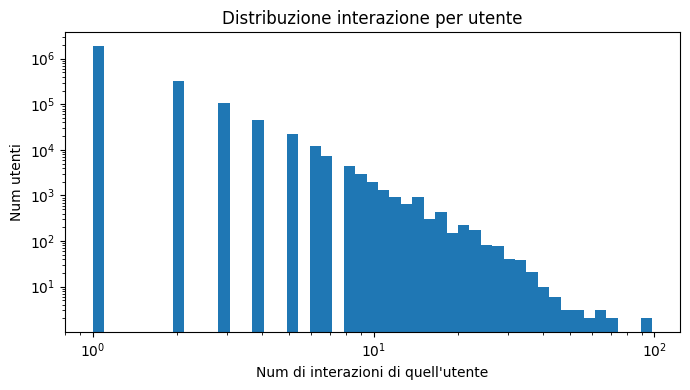

In [129]:
plt.figure(figsize=(7,4))
counts=user_counts[user_counts>0]
#crea 50 intervalli su scala logaritmica tra 10^0=1 e max num di interazioni=10^2=100 circa (in realtà 98)
#essendo molto sbilanciata, tanti utenti hanno poche interazioni, pochi utenti ne hanno molte.super
spaces=np.logspace(0,np.log10(counts.max()),50) if counts.max()>1 else 1 
plt.hist(counts,bins=spaces)
plt.xscale("log")
plt.yscale("log")
plt.title("Distribuzione interazione per utente")
plt.xlabel("Num di interazioni di quell'utente")
plt.ylabel("Num utenti")
plt.tight_layout()
plt.show()

## 9 analisi dei prodotti
vogliamo evitare prodotti con pochissimi rating, ma anche evitare filtri troppo aggressivi

In [130]:
item_counts=interactions_df["parent_asin"].value_counts() #contiamo quante interazioni ha ogni prodotto
item_summary=analyze_quantilies(item_counts,"products") #riepilogo della distribuzione
item_summary

,entity,num_entities,mean,median:,min,p25,p75,p90,p95,p99,max
0,products,22974,150.046618,52.000000,1,20.000000,137.000000,317.000000,536.000000,"1,540.700000",19205


In [131]:
#soglie di thresholds da testare
item_thresholds=[1,2,3,4,5,6,7,8,9,10,20,50,100]
rows=[]
for t in item_thresholds:
    valid_items=item_counts[item_counts>=t].index
    filtered=interactions_df[interactions_df["parent_asin"].isin(valid_items)]
    rows.append({ #aggiungiamo dizionario con le statistiche sulla soglia corrente
        "min_product_interactions":t,
        "num_users":filtered["user_id"].nunique(),
        "num_products_remaining":filtered["parent_asin"].nunique(),
        "num_interactions":len(filtered),
        "percentage_users":filtered["user_id"].nunique()/interactions_df["user_id"].nunique()*100,
        "percentage_products":filtered["parent_asin"].nunique()/interactions_df["parent_asin"].nunique()*100,
        "percentage_Interactions":len(filtered)/len(interactions_df)*100
    })

item_thresholds_table=pd.DataFrame(rows)
item_thresholds_table

,min_product_interactions,num_users,num_products_remaining,num_interactions,percentage_users,percentage_products,percentage_Interactions
0,1,2434619,22974,3447171,100.000000,100.000000,100.000000
1,2,2434487,22734,3446931,99.994578,98.955341,99.993038
2,3,2434226,22459,3446381,99.983858,97.758336,99.977083
3,4,2433774,22160,3445484,99.965292,96.456864,99.951061
4,5,2433132,21853,3444256,99.938923,95.120571,99.915438
5,6,2432297,21502,3442501,99.904626,93.592757,99.864527
6,7,2431243,21152,3440401,99.861334,92.069296,99.803607
7,8,2430221,20862,3438371,99.819356,90.806999,99.744718
8,9,2428891,20550,3435875,99.764727,89.448942,99.672311
9,10,2427288,20211,3432824,99.698885,87.973361,99.583804


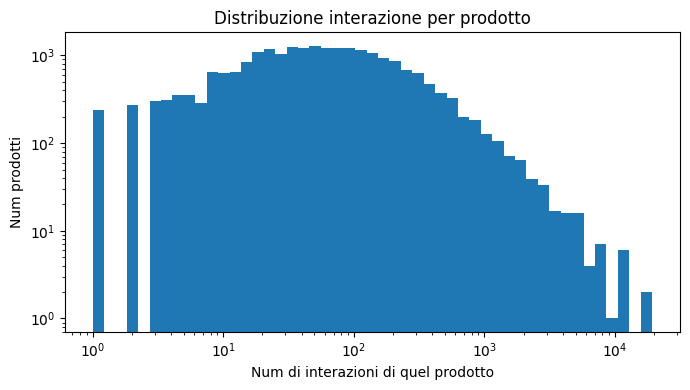

In [132]:
plt.figure(figsize=(7,4))
counts=item_counts[item_counts>0]
spaces=np.logspace(0,np.log10(counts.max()),50) if counts.max()>1 else 1 
plt.hist(counts,bins=spaces)
plt.xscale("log")
plt.yscale("log")
plt.title("Distribuzione interazione per prodotto")
plt.xlabel("Num di interazioni di quel prodotto")
plt.ylabel("Num prodotti")
plt.tight_layout()
plt.show()

,interactions_per_product,num_products,percentage_products
0,1-4,1121,4.879429
1,5-9,1642,7.147210
2,10-19,2950,12.840602
3,20-49,5493,23.909637
4,50-99,4245,18.477409
5,≥100,7523,32.745713


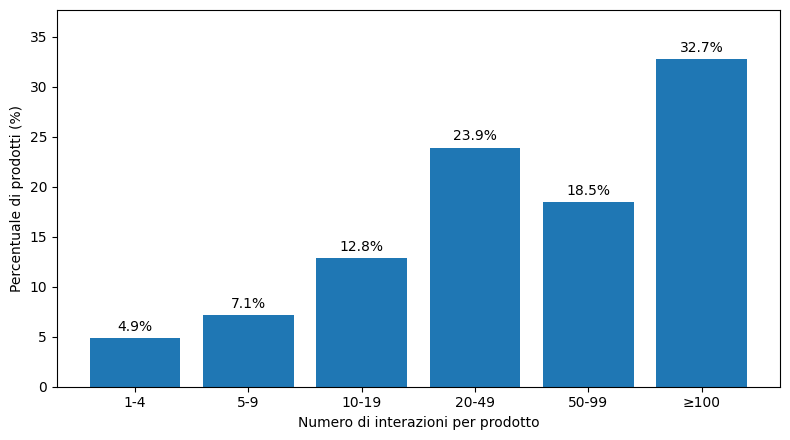

In [133]:
# Distribuzione dei prodotti per numero di interazioni
# Raggruppamento in fasce per una visualizzazione più leggibile nella tesi

item_interaction_groups = pd.Series({
    "1-4": ((item_counts >= 1) & (item_counts <= 4)).sum(),
    "5-9": ((item_counts >= 5) & (item_counts <= 9)).sum(),
    "10-19": ((item_counts >= 10) & (item_counts <= 19)).sum(),
    "20-49": ((item_counts >= 20) & (item_counts <= 49)).sum(),
    "50-99": ((item_counts >= 50) & (item_counts <= 99)).sum(),
    "≥100": (item_counts >= 100).sum()
})

item_interaction_pct = (
    item_interaction_groups / item_interaction_groups.sum() * 100
)

item_interaction_distribution = pd.DataFrame({
    "interactions_per_product": item_interaction_groups.index,
    "num_products": item_interaction_groups.values,
    "percentage_products": item_interaction_pct.values
})

display(item_interaction_distribution)

plt.figure(figsize=(8, 4.5))

bars = plt.bar(
    item_interaction_groups.index,
    item_interaction_pct.values
)

plt.xlabel("Numero di interazioni per prodotto")
plt.ylabel("Percentuale di prodotti (%)")

plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in item_interaction_pct.values],
    padding=3
)

plt.ylim(0, item_interaction_pct.max() * 1.15)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR / "product_interactions_distribution_grouped.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10 analisi QA per prodotto
inizialmente potrebbe non essere aggiunto, ma è utile vedere ora quante domande/risposte sono associate ai prodotti

In [134]:
qa_counts=qa_df["parent_asin"].value_counts() #conta quante righe associate a ciascun prodotto
total_products=items_df["parent_asin"].nunique() #calcola n tot di prodotti nel catalogo

products_with_qa=qa_counts.shape[0] #num prodotti con almeno una riga qa
total_qa_rows=len(qa_df)

qa_overview=pd.DataFrame([{
    "tot_products":total_products,#num tot di prodotti
    "products_with_qa":products_with_qa,
    "percentage_with_qa":products_with_qa/total_products*100,
    "total_qa_rows":total_qa_rows,
    "mean-qa_perproducts":qa_counts.mean(),
    "median-qa_perproducts":qa_counts.median(),
    "max-qa_perproduct":qa_counts.max()
}])
qa_summary=analyze_quantilies(qa_counts, "products_with_qa")
display(qa_overview)
display(qa_summary)

,tot_products,products_with_qa,percentage_with_qa,total_qa_rows,mean-qa_perproducts,median-qa_perproducts,max-qa_perproduct
0,22974,22974,100.000000,180976,7.877427,9.000000,40


,entity,num_entities,mean,median:,min,p25,p75,p90,p95,p99,max
0,products_with_qa,22974,7.877427,9.000000,1,6.000000,10.000000,10.000000,10.000000,10.000000,40


## 11 Profilo prodotti rating + qa + metadati
creiamo una vista sintetica per analisi

In [135]:
profile_col=[
    col for col in  ["parent_asin","title","category","avg_rating","num_ratings","price","store"] #scorre colonne candidate
    if col in items_df.columns #list comprehension, crea lista con colonne che esistono davvero dentro dentro l'altra lista
]

item_profile=items_df[profile_col].copy()#crea tab con solo quelle colonne
item_profile=item_profile.merge(
    item_counts.rename("interaction_count"), #rinomina conteggi dei rating
    left_on="parent_asin",  #merge usa parentasin come chiave nel dataframe di sx
    right_index=True, #merge usa indice della serie di destra come chiave
    how="left", #left join per mantenere tutti i prodotti anche se non hanno quel conteggio
)

item_profile=item_profile.merge(
    qa_counts.rename("qa_count"),
    left_on="parent_asin",
    right_index=True,
    how="left",
)
item_profile["interaction_count"] =item_profile["interaction_count"].fillna(0).astype(int) #sostituisce mancanti con 0 e converte a interi
item_profile["qa_count"]= item_profile["qa_count"].fillna(0).astype(int) #sostituisce mancanti con 0 e converte a interi
item_profile.sort_values("interaction_count",ascending=False).head(20) #mostra ordinati dal piu interagito al meno

,parent_asin,title,category,avg_rating,num_ratings,price,store,interaction_count,qa_count
9343,B00BWF5U0M,SABRENT 4 Port USB 2.0 Data Hub with Individual LED lit Power Switches [Charging NOT Supported] for Mac & PC (HB-UMLS),Computers,4.600000,119789,8.990000,SABRENT,19205,10
9949,B0043T7FXE,"Logitech M570 Wireless Trackball Mouse – Ergonomic Design with Sculpted Right-Hand Shape, Compatible with Apple Mac ...",All Electronics,4.600000,46483,63.430000,Logitech,15808,10
1015,B003NR57BY,"Logitech M510 Wireless Computer Mouse – Comfortable Shape with USB Unifying Receiver, with Back/Forward Buttons and ...",All Electronics,4.600000,28251,23.500000,Logitech,12503,10
297,B00F0DD0I6,NETGEAR Nighthawk Smart Wi-Fi Router (R7000) - AC1900 Wireless Speed (Up to 1900 Mbps) | Up to 1800 Sq Ft Coverage &...,Computers,4.300000,22198,65.780000,NETGEAR,12426,10
14959,B00BIFNTMC,"Anker 2.4G Wireless Vertical Ergonomic Optical Mouse, 800 / 1200 /1600 DPI, 5 Buttons for Laptop, Desktop, PC, Macbo...",Computers,4.200000,46398,18.990000,Anker,11211,10
20672,B00IVPU786,Samsung 32GB up to 48MB/s EVO Class 10 Micro SDHC Card with Adapter (MB-MP32DA/AM),Electronics,4.500000,18234,NaN,SAMSUNG,11017,10
7496,B00IVPU7AO,Samsung EVO 64GB 48/MB/s Micro SDXC Memory Card with Adapter up to (MB-MP64DA/AM),Computers,4.500000,17000,47.000000,SAMSUNG,10927,10
2689,B001FWYGJS,"TP-Link N300 Wireless Extender, Wi-Fi Router (TL-WR841N) - 2 x 5dBi High Power Antennas, Supports Access Point, WISP...",Computers,4.200000,73817,20.990000,TP-Link,10741,10
673,B006JH8T3S,"Logitech HD Pro Webcam C920, Widescreen Video Calling and Recording, 1080p Camera, Desktop or Laptop Webcam (Discont...",Computers,4.600000,30686,64.490000,Logitech,9123,10
4442,B00IF70T4M,"1byone TV Antenna, Amplified HDTV Antenna with Detachable Amplifier Signal Booster, USB Power Supply and 10 Feet Hig...",Home Audio & Theater,3.800000,11287,NaN,1 BY ONE,8530,10


## 12 sparsità della matrice utente-prodotto

In [136]:
#funzione per calcoalre sparsità della matrice
def sparsity_statistics(df: pd.DataFrame, user_col="user_id", item_col="parent_asin")->dict:
    num_users=df[user_col].nunique() #conta n utenti unici
    num_items=df[item_col].nunique()#num prodotti unici
    num_interactions=len(df) #num interazioni
    possible_pairs=num_users*num_items #coppie possibili nella matrice completa
    density=num_interactions/possible_pairs if possible_pairs else np.nan #densità come interazioni osservate/coppie possibili

    return{
        "num_users":num_users,
        "num_items":num_items,
        "num_interactions":num_interactions,
        "possible_pairs":possible_pairs,
        "density":density,
        "density_percentage": density*100 if not pd.isna(density) else np.nan, 
        "sparsity_percentage": (1-density)*100 if not pd.isna(density) else np.nan, #sparsità come 1-densità
    }
base_sparsity=sparsity_statistics(interactions_df)
base_sparsity_df=pd.DataFrame([base_sparsity])
base_sparsity_df

,num_users,num_items,num_interactions,possible_pairs,density,density_percentage,sparsity_percentage
0,2434619,22974,3447171,55932936906,0.000062,0.006163,99.993837


## 13 confronto di configurazioni candidate

In [137]:
#funz per applicare filtro utenti-prodotti
def func_filter(
    df: pd.DataFrame,
    min_user_int:int, #soglia minima interazione per utente
    min_item_int:int, #soglia minima per interazioni prodotto
    user_col:str="user_id",
    item_col:str="parent_asin",
    max_iter:int=50, #max iterazioni, evitare loop
)->tuple[pd.DataFrame,pd.DataFrame]:
    current=df.copy()
    history=[]
    for step in range(1,max_iter+1):
        #salviamo num precedenti
        rows_before=len(current)
        users_before=current[user_col].nunique()
        items_before=current[item_col].nunique()
        if min_item_int>1 and len(current)>0: #se la soglia prodotto è maggiore di 1 e la tabella non è vuota, filtra i prodotti
            item_counts_step=current[item_col].value_counts() #conta interazioni
            valid_items=item_counts_step[item_counts_step>=min_item_int].index #seleziona prodotti
            current=current[current[item_col].isin(valid_items)] #tiene solo interazioni dei prodotti che abbiamo tenuto
        if min_user_int>1 and len(current)>0: #se la soglia utente >1 e tab non vuota
            user_counts_step=current[user_col].value_counts()
            valid_users=user_counts_step[user_counts_step>=min_user_int].index 
            current=current[current[user_col].isin(valid_users)]
        #contiamo num dopo filtraggio
        rows_after=len(current)
        users_after=current[user_col].nunique()
        items_after=current[item_col].nunique()
        history.append({ #aggiunge alla storia le statistiche dell'iterazione
            "iteration":step,
            "min_user_int":min_user_int,
            "min_item_int":min_item_int,
            "rows_before":rows_before,
            "rows_after":rows_after,
            "rows_removed":rows_before-rows_after,
            "users_before":users_before,
            "users_after":users_after,
            "users_removed":users_before-users_after,
            "items_before":items_before,
            "items_after":items_after,
            "items_removed":items_before-items_after,
            
        })
        if rows_after==rows_before: #stoppa se non ci sono righe da rimuovere
            break
    return current.reset_index(drop=True), pd.DataFrame(history) #ritorna dataframe filtrato e la storia delle iterazioni

In [138]:
user_thresholds_grid=[2,3,4,5]
item_thresholds_grid=[5,6,7,8,9,10,20]
candidate_rows=[] #lista dove salveremo una riga di risultati per ogni combinazione
candidate_histories={} #diz dove salveremo la history di ogni config

#num tot prima
total_users=interactions_df["user_id"].nunique()
total_items=interactions_df["parent_asin"].nunique()
total_interactions=len(interactions_df)

for min_u in user_thresholds_grid:
    for min_i in item_thresholds_grid:
        conf_used=f"user{min_u}_item{min_i}" #nome della configurazione usata ora
        filtered_df,history_df=func_filter( #applichiamo filtro
            df=interactions_df,
            min_user_int=min_u,
            min_item_int=min_i,
            user_col="user_id",
            item_col="parent_asin",
            max_iter=50
        )
        candidate_histories[conf_used]=history_df #salviamo history
        #num tot dopo
        num_users=filtered_df["user_id"].nunique()
        num_items=filtered_df["parent_asin"].nunique()
        num_interactions=len(filtered_df)
        possible_pairs=num_users*num_items
        #calcolo densità e numeri medi interazioni per prodotti e per utenti
        density=num_interactions/possible_pairs if possible_pairs>0 else 0
        avg_interactions_peruser=num_interactions/num_users if num_users>0 else 0
        avg_interactions_peritem=num_interactions/num_items if num_items>0 else 0
        candidate_rows.append({ #salviamo le statistiche della configurazione corrente
            "config_name":conf_used,
            "min_user_int":min_u,
            "min_item_int":min_i,
            "num_users":num_users,
            "num_items":num_items,
            "num_interactions":num_interactions,
            "pct_users":num_users/total_users*100,
            "pct_items":num_items/total_items*100,
            "pct_interactions":num_interactions/total_interactions*100,
            "density_pct":density*100,
            "avg_interactions_peruser":avg_interactions_peruser,
            "avg_interactions_peritem":avg_interactions_peritem,
            "iterations":len(history_df),
            "supports_train_val_test":min_u>=3 #1 per training, 1 per val, 1 per test, teoricamente lo teniamo come minimo
        })

candidate_filters_df=pd.DataFrame(candidate_rows)
candidate_filters_df=candidate_filters_df.sort_values(
    ["min_user_int","min_item_int"]
).reset_index(drop=True)
candidate_filters_df



,config_name,min_user_int,min_item_int,num_users,num_items,num_interactions,pct_users,pct_items,pct_interactions,density_pct,avg_interactions_peruser,avg_interactions_peritem,iterations,supports_train_val_test
0,user2_item5,2,5,532459,19980,1538233,21.870321,86.967877,44.623055,0.014459,2.888923,76.988639,4,False
1,user2_item6,2,6,531078,19344,1533675,21.813598,84.199530,44.490830,0.014929,2.887853,79.284274,4,False
2,user2_item7,2,7,529497,18736,1528448,21.748660,81.553060,44.339199,0.015407,2.886604,81.578138,4,False
3,user2_item8,2,8,527640,18144,1522455,21.672385,78.976234,44.165346,0.015903,2.885405,83.909557,5,False
4,user2_item9,2,9,525574,17568,1515792,21.587526,76.469052,43.972057,0.016417,2.884070,86.281421,4,False
5,user2_item10,2,10,523356,16999,1508460,21.496423,73.992339,43.759361,0.016956,2.882283,88.738161,4,False
6,user2_item20,2,20,497112,12723,1421643,20.418472,55.379995,41.240861,0.022477,2.859804,111.738033,5,False
7,user3_item5,3,5,202021,17589,870005,8.297849,76.560460,25.238232,0.024484,4.306508,49.463017,5,True
8,user3_item6,3,6,200348,16671,862086,8.229132,72.564638,25.008507,0.025811,4.302943,51.711715,5,True
9,user3_item7,3,7,198495,15839,853404,8.153021,68.943153,24.756648,0.027144,4.299373,53.879917,5,True


In [139]:
candidate_filters_path=ANALYSIS_DIR/"notebook02_candidate_filter_comparison.csv"
candidate_filters_df.to_csv(candidate_filters_path,index=False)
print("Tabella salvata in:",candidate_filters_path)

Tabella salvata in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\analysis\notebook02_candidate_filter_comparison.csv


## 14 scelta della configurazione
Scegliamo utenti con interazioni >=3 e prodotti con interazioni >=8

In [140]:
SELECTED_CONFIG="user3_item8" #puoi cambiare per sceglierne altre

selected_config_row=candidate_filters_df[
    candidate_filters_df["config_name"]==SELECTED_CONFIG
].iloc[0] #recuperiamo riga della config scelta

selected_min_user_int=int(selected_config_row["min_user_int"])
selected_min_item_int=int(selected_config_row["min_item_int"])

selected_interactions_df,selected_history_df=func_filter( #applichiamo filtro per ottenere dataset candidato per il prossimo notebook03
    df=interactions_df,
    min_user_int=selected_min_user_int,
    min_item_int=selected_min_item_int,
    user_col="user_id",
    item_col="parent_asin",
    max_iter=50,
)

print("Configurazione scelta:",SELECTED_CONFIG)
print("Utenti rimasti nel dataset:",selected_interactions_df["user_id"].nunique())
print("Prodotti rimasti nel dataset:",selected_interactions_df["parent_asin"].nunique())
print("Interazioni rimaste:",len(selected_interactions_df))
display(selected_history_df)
display(pd.DataFrame([selected_config_row]))

Configurazione scelta: user3_item8
Utenti rimasti nel dataset: 196509
Prodotti rimasti nel dataset: 15069
Interazioni rimaste: 844060


,iteration,min_user_int,min_item_int,rows_before,rows_after,rows_removed,users_before,users_after,users_removed,items_before,items_after,items_removed
0,1,3,8,3447171,885128,2562043,2434619,205338,2229281,22974,20679,2295
1,2,3,8,885128,846062,39066,205338,196945,8393,20679,15232,5447
2,3,3,8,846062,844126,1936,196945,196521,424,15232,15075,157
3,4,3,8,844126,844060,66,196521,196509,12,15075,15069,6
4,5,3,8,844060,844060,0,196509,196509,0,15069,15069,0


,config_name,min_user_int,min_item_int,num_users,num_items,num_interactions,pct_users,pct_items,pct_interactions,density_pct,avg_interactions_peruser,avg_interactions_peritem,iterations,supports_train_val_test
10,user3_item8,3,8,196509,15069,844060,8.071448,65.591538,24.485585,0.028504,4.295274,56.013007,5,True


In [141]:
selected_sparsity=sparsity_statistics(selected_interactions_df) #sparsità
selected_sparsity_df=pd.DataFrame([selected_sparsity]) #la convertiamo per mostrarla in tabella

sparsity_comp_df=pd.concat(
    [
        base_sparsity_df.assign(dataset="completo"),
        selected_sparsity_df.assign(dataset=SELECTED_CONFIG)
    ],
    ignore_index=True,
)
sparsity_comp_df=sparsity_comp_df[
    ["dataset","num_users","num_items","num_interactions","possible_pairs","density_percentage","sparsity_percentage"]
]
sparsity_comp_df

,dataset,num_users,num_items,num_interactions,possible_pairs,density_percentage,sparsity_percentage
0,completo,2434619,22974,3447171,55932936906,0.006163,99.993837
1,user3_item8,196509,15069,844060,2961194121,0.028504,99.971496


In [142]:
selected_summary={
    "selected_config_name":SELECTED_CONFIG,
    "min_user_interactions":selected_min_user_int,
    "min_item_interactions":selected_min_item_int,
    "num_users":int(selected_interactions_df["user_id"].nunique()),
    "num_items":int(selected_interactions_df["parent_asin"].nunique()),
    "num_interactions":int(len(selected_interactions_df)),
    "density_pct":float(selected_sparsity["density_percentage"]),
    "sparsity_pct":float(selected_sparsity["sparsity_percentage"]),
}
selected_config_path=ANALYSIS_DIR/"notebook02_selected_filter_config.json" #salviamo in file json la configurazione scelta
selected_config_path.write_text(
    json.dumps(selected_summary,indent=2), encoding="utf-8", #convertiamo dizionario in testo json formattato
)
print("Configurazione scelta salvata in:",selected_config_path)
selected_summary

Configurazione scelta salvata in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\analysis\notebook02_selected_filter_config.json


{'selected_config_name': 'user3_item8',
 'min_user_interactions': 3,
 'min_item_interactions': 8,
 'num_users': 196509,
 'num_items': 15069,
 'num_interactions': 844060,
 'density_pct': 0.02850404146131965,
 'sparsity_pct': 99.97149595853868}

## 15 dataset candidati

In [143]:
selected_products=selected_interactions_df["parent_asin"].unique() #elenco prodotti rimasti nelle interazioni filtrate
selected_items_df=items_df[
    items_df["parent_asin"].isin(selected_products)
].copy() #filtriamo la tabella prodotti tenendo solo quelli rimasti nel dataset candidato

selected_qa_df=qa_df[
    qa_df["parent_asin"].isin(selected_products)
].copy() #filtriamo qa tenendo solo prodotti rimasti nel dataset candidato

# i 3 path in cui salvare
selected_interactions_path=PROCESSED_DIR/f"candidate_interactions_{SELECTED_CONFIG}.parquet"
selected_items_path=PROCESSED_DIR/f"candidate_items_{SELECTED_CONFIG}.parquet"
selected_qa_path=PROCESSED_DIR/f"candidate_qa_{SELECTED_CONFIG}.parquet"
#salviamo
selected_interactions_df.to_parquet(selected_interactions_path,index=False)
selected_items_df.to_parquet(selected_items_path,index=False)
selected_qa_df.to_parquet(selected_qa_path,index=False)

print("Interazioni del dataset candidato salvate in:",selected_interactions_path)
print("Prodotti del dataset candidato salvati in:",selected_items_path)
print("QA dei prodotti candidati salvati in:",selected_qa_path)

print("selected_interactions_df:",selected_interactions_df.shape)
print("selected_items_df:",selected_items_df.shape)
print("selected_qa_df:",selected_qa_df.shape)

Interazioni del dataset candidato salvate in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\candidate_interactions_user3_item8.parquet
Prodotti del dataset candidato salvati in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\candidate_items_user3_item8.parquet
QA dei prodotti candidati salvati in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\candidate_qa_user3_item8.parquet
selected_interactions_df: (844060, 7)
selected_items_df: (15069, 12)
selected_qa_df: (128151, 8)
